# CLFG forcing comparison

May 22–28, 2026 UTC. The 20 m and 100 m TopoPyScale runs use the same HRRR-AK inputs, site coordinates, and terrain window. Both are integration tests that retain below-ground HRRR-AK values. Use these figures to inspect the workflow and terrain sensitivity. The CLFG field record contains a snow-depth observation and provides no hourly meteorological reference.

The notebook reads the workflow outputs described in [the downscaling README](README.md).

In [1]:
import json
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

from IPython.display import display

folder = Path.cwd()
if (folder / "downscaling").is_dir():
    folder = folder / "downscaling"
outputs = folder / "outputs"
comparison = outputs / "clfg_topopyscale_integration_comparison.csv"
if not comparison.is_file():
    raise FileNotFoundError(f"{comparison}. See the downscaling README for input generation.")

data = pd.read_csv(comparison, parse_dates=["time_utc"], index_col="time_utc")
diagnostics = {
    resolution: json.loads(
        (outputs / f"clfg_topopyscale_{resolution}m" / "profile_diagnostics.json").read_text()
    )
    for resolution in (20, 100)
}

raw_color = "#59616b"
colors = {20: "#006d77", 100: "#bb531a"}
plt.rcParams.update({"figure.dpi": 115, "axes.spines.top": False, "axes.spines.right": False})


def format_time(ax, label="Date and time (UTC)"):
    locator = mdates.AutoDateLocator(minticks=4, maxticks=8)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    ax.set_xlabel(label)
    ax.grid(axis="y", alpha=0.22)

## Temperature at CLFG

The fixed-lapse-rate series uses the 2 m ArcticDEM elevation and the existing 6 K/km correction. A separate panel shows the signed 20 m minus 100 m difference because the two TopoPyScale series nearly overlap.

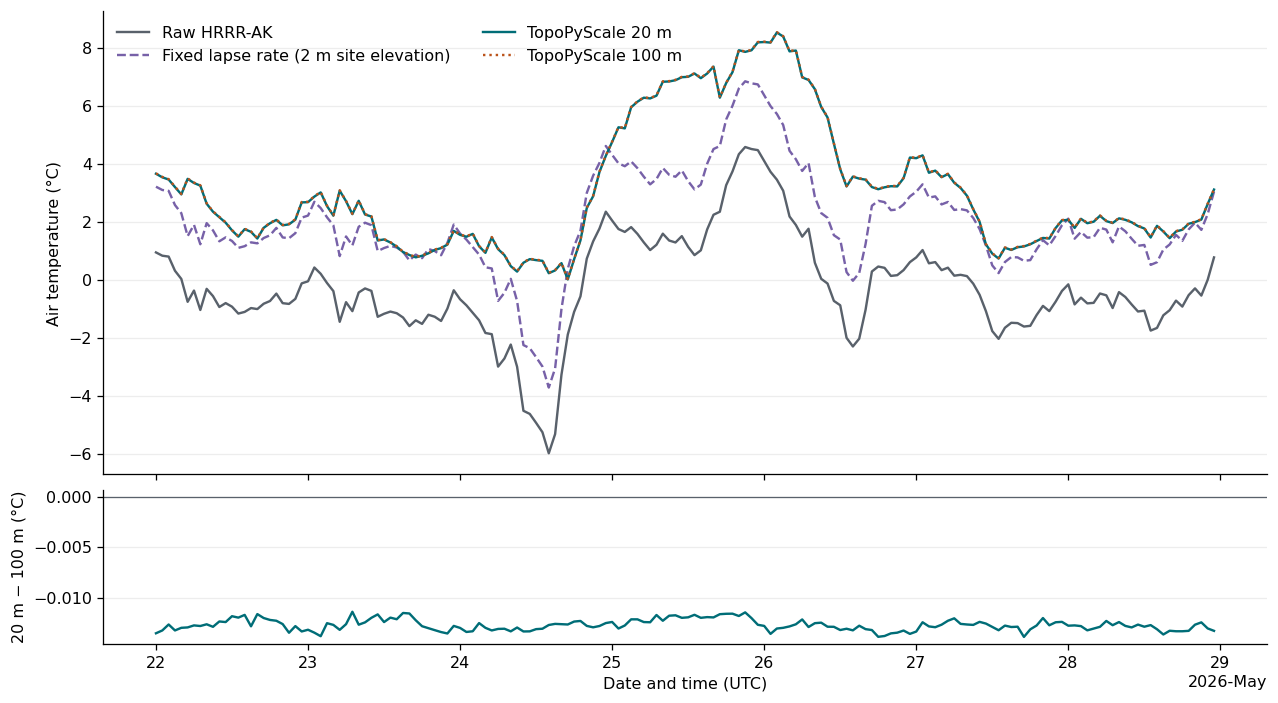

,Mean temperature (°C),Mean change from raw (°C)
Raw HRRR-AK,-0.26,0.00
Fixed lapse rate (2 m site elevation),2.01,2.27
TopoPyScale 20 m,3.10,3.37
TopoPyScale 100 m,3.12,3.38


In [2]:
temperature = pd.DataFrame({
    "Raw HRRR-AK": data["temp"] - 273.15,
    "Fixed lapse rate (2 m site elevation)": data["temp_lapse_2m_K"] - 273.15,
    **{f"TopoPyScale {res} m": data[f"topopyscale_{res}m_temperature_K"] - 273.15
       for res in (20, 100)},
})
delta_t = temperature["TopoPyScale 20 m"] - temperature["TopoPyScale 100 m"]

fig, (ax, delta) = plt.subplots(2, 1, figsize=(11, 6), sharex=True,
                               height_ratios=[3, 1], layout="constrained")
for label, color, style in zip(temperature, [raw_color, "#7761a8", colors[20], colors[100]],
                               ["-", "--", "-", ":"]):
    ax.plot(temperature.index, temperature[label], label=label, color=color, linestyle=style)
ax.set_ylabel("Air temperature (°C)")
ax.legend(ncol=2, frameon=False, loc="upper left")
ax.grid(axis="y", alpha=0.22)
delta.axhline(0, color=raw_color, linewidth=0.8)
delta.plot(delta_t.index, delta_t, color=colors[20])
delta.set_ylabel("20 m − 100 m (°C)")
format_time(delta)
plt.show()

display(pd.DataFrame({
    "Mean temperature (°C)": temperature.mean(),
    "Mean change from raw (°C)": temperature.subtract(temperature["Raw HRRR-AK"], axis=0).mean(),
}).round(2))

## Incoming radiation

The upper panels compare hourly shortwave and longwave radiation against raw HRRR-AK. The lower panel zooms in on the day with the largest shortwave difference between terrain resolutions.

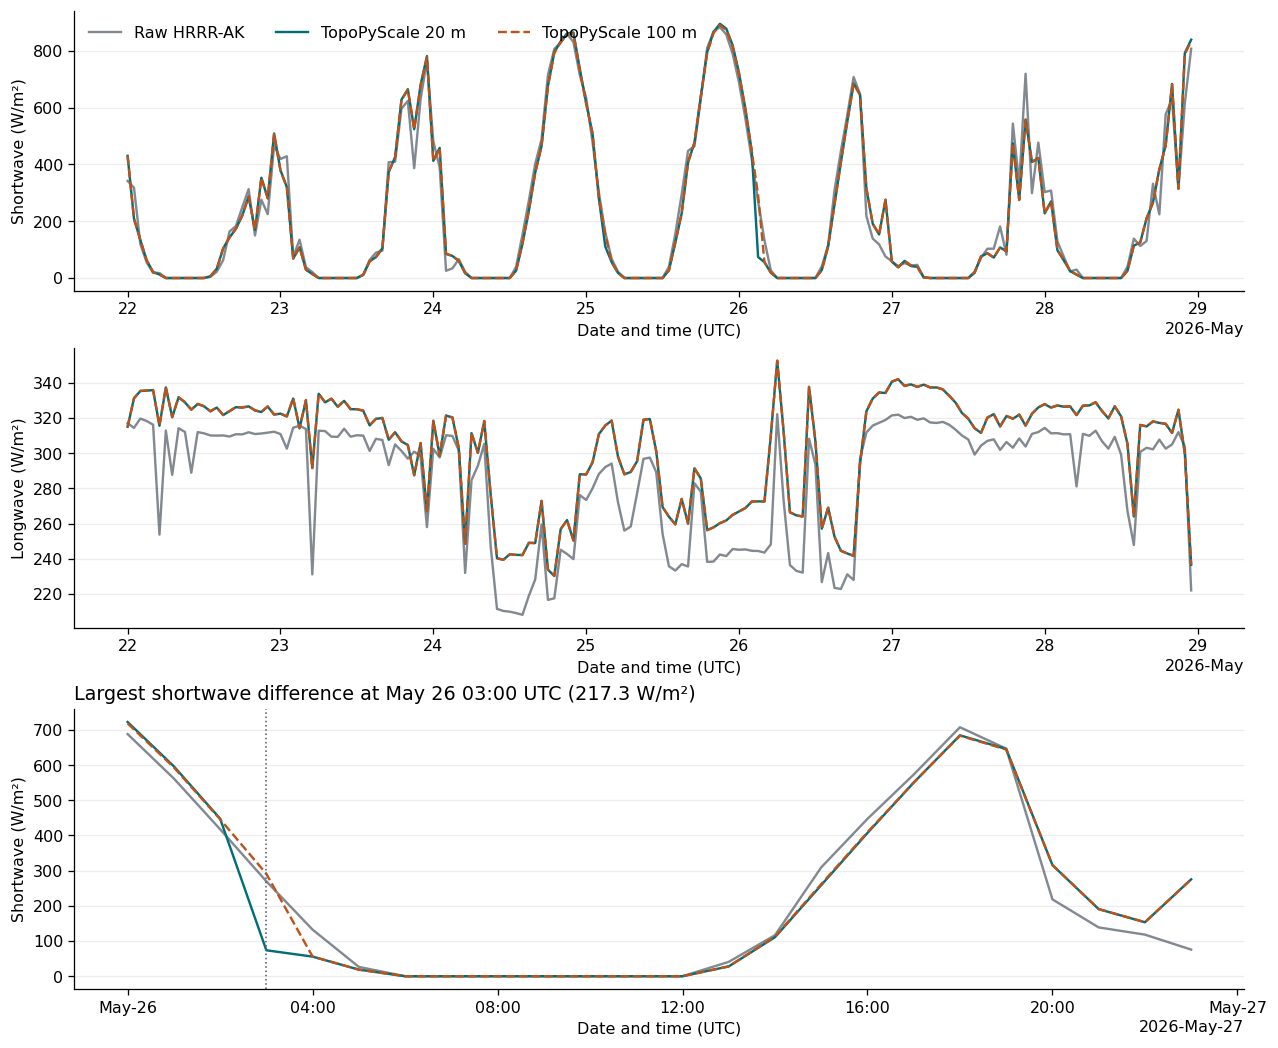

,Weekly shortwave energy (kWh/m²)
Raw HRRR-AK,36.66
TopoPyScale 20 m,36.51
TopoPyScale 100 m,36.71


In [3]:
shortwave = data[[f"topopyscale_{res}m_shortwave_W_m2" for res in (20, 100)]]
delta_sw = shortwave.iloc[:, 0] - shortwave.iloc[:, 1]
peak_hour = delta_sw.abs().idxmax()
day = data.loc[peak_hour.strftime("%Y-%m-%d")]

fig, axes = plt.subplots(3, 1, figsize=(11, 9), layout="constrained")
for ax, series, kind, raw in [
    (axes[0], data, "shortwave", "swrad"),
    (axes[1], data, "longwave", "lwrad"),
    (axes[2], day, "shortwave", "swrad"),
]:
    ax.plot(series.index, series[raw], color=raw_color, alpha=0.75, label="Raw HRRR-AK")
    for res in (20, 100):
        ax.plot(series.index, series[f"topopyscale_{res}m_{kind}_W_m2"],
                color=colors[res], label=f"TopoPyScale {res} m",
                linestyle="-" if res == 20 else "--")
    ax.set_ylabel(f"{kind.capitalize()} (W/m²)")
    format_time(ax)
axes[0].legend(frameon=False, ncol=3)
axes[2].axvline(peak_hour, color=raw_color, linestyle=":", linewidth=1)
axes[2].set_title(f"Largest shortwave difference at {peak_hour:%b %d %H:%M} UTC "
                  f"({abs(delta_sw.loc[peak_hour]):.1f} W/m²)", loc="left")
plt.show()

display(pd.DataFrame({
    "Weekly shortwave energy (kWh/m²)": {
        "Raw HRRR-AK": data["swrad"].sum() / 1000,
        **{f"TopoPyScale {res} m": data[f"topopyscale_{res}m_shortwave_W_m2"].sum() / 1000
           for res in (20, 100)},
    }
}).round(2))

## Do the pressure profiles bracket the site?

A usable bracket requires two pressure levels in the same native HRRR column, one above and one below the DEM target, with both levels above model ground. The nearby-cell count answers whether any native column within 12 km had a bracket in each hour. It describes available input support. The integration runs used the stock kernel with unmasked pressure fields.

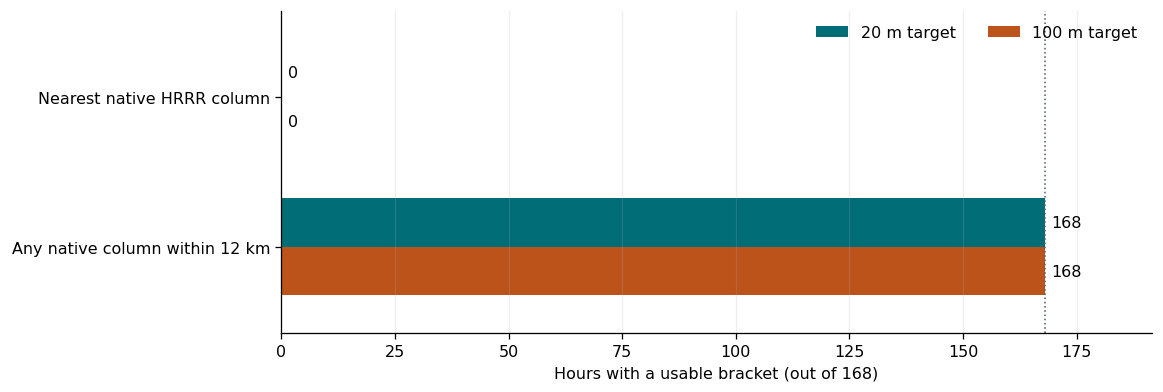

,20 m target,100 m target
Target DEM elevation (m),652.5,650.6
Nearest native HRRR terrain (m),928.3,928.3


In [4]:
coverage = pd.DataFrame({
    f"{res} m target": [
        entry["hours_with_nearest_usable_bracket"],
        entry["hours_with_usable_bracket_within_12km"],
    ]
    for res, entry in diagnostics.items()
}, index=["Nearest native HRRR column", "Any native column within 12 km"])
hours = diagnostics[20]["hours"]
fig, ax = plt.subplots(figsize=(10, 3.3), layout="constrained")
coverage.plot.barh(ax=ax, color=[colors[20], colors[100]], width=0.65)
for bars in ax.containers:
    ax.bar_label(bars, padding=4, fmt="%d")
ax.axvline(hours, color=raw_color, linestyle=":", linewidth=1)
ax.set_xlim(0, hours * 1.14)
ax.set_xlabel(f"Hours with a usable bracket (out of {hours})")
ax.legend(frameon=False, loc="upper right", ncol=2)
ax.grid(axis="x", alpha=0.2)
ax.invert_yaxis()
plt.show()

display(pd.DataFrame({
    f"{res} m target": {
        "Target DEM elevation (m)": entry["target_elevation_m"],
        "Nearest native HRRR terrain (m)": entry["nearest_native_terrain_m"],
    }
    for res, entry in diagnostics.items()
}).round(1))